In [ ]:
Ваша задача — создать на PyTorch собственный ИИ-античит, 
который по статистике игрока должен определить один из трёх классов: Обычный игрок / Сильный игрок / Подозрительный игрок. 
    Все команды используют одинаковые входные характеристики: Kills — количество убийств, Deaths — смертей, Accuracy — точность стрельбы (%), 
    HeadshotPercent — процент попаданий в голову, DamagePerMatch — средний урон за матч, SurvivalRate — процент выживаемости, 
    AverageKillDistance — средняя дистанция убийства, ShotsFired — количество выстрелов, ShotsHit — количество попаданий, 
    ReactionTime — среднее время реакции в миллисекундах. Создайте собственный датасет минимум из 600 игроков. 
Вы сами решаете, какими характеристиками обычно обладают обычные, сильные и подозрительные игроки. 
Не делайте классы слишком очевидными: добавьте шум, пересечения и необычных игроков — сильный игрок вполне может иметь 70% headshot, 
а подозрительный игрок специально играть плохо. 
    Нельзя определять класс обычными if/else непосредственно во время предсказания — решение должна принимать нейронная сеть. 
        Разделите данные на обучающую и тестовую выборки, выполните необходимую предобработку и создайте нейронную сеть минимум с двумя скрытыми слоями. 
    Самостоятельно определите, что необходимо использовать для этой задачи на выходе — Sigmoid или Softmax — и на защите объясните почему. 
            
Проведите эксперимент минимум с тремя функциями активации скрытых слоёв из Sigmoid, Tanh, ReLU, LeakyReLU, SiLU, сравните результаты и выберите лучший вариант. 
            Создайте функцию predict_player(), которая принимает характеристики любого игрока и выводит результат, 
            например: Обычный — 4% | Сильный — 23% | Подозрительный — 73% → Вердикт: ПОДОЗРИТЕЛЬНЫЙ.

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
import torch
from torch import nn
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(17)

import numpy as np

# ---1--- Генерація даних
n = 600
labels = ["Normal", "Strong", "Suspicious"]
data = []

for i in range(n):
    label = np.random.choice(labels, p=[0.4, 0.3, 0.3])
    
    if label == "Normal":
        kills = np.random.randint(2, 15)
        deaths = np.random.randint(5, 15)
        accuracy = np.random.uniform(0.2, 0.5)
        headshot = np.random.uniform(0.1, 0.3)
        dmg = np.random.randint(200, 800)
        surv = np.random.uniform(0.3, 0.6)
        dist = np.random.randint(500, 2000)
        shots_fired = np.random.randint(200, 1000)
        shots_hit = int(shots_fired * accuracy)
        react = np.random.randint(250, 400)

    elif label == "Strong":
        kills = np.random.randint(10, 30)
        deaths = np.random.randint(2, 10)
        accuracy = np.random.uniform(0.4, 0.7)
        headshot = np.random.uniform(0.2, 0.7)
        dmg = np.random.randint(800, 2000)
        surv = np.random.uniform(0.5, 0.9)
        dist = np.random.randint(1000, 3000)
        shots_fired = np.random.randint(500, 2000)
        shots_hit = int(shots_fired * accuracy)
        react = np.random.randint(180, 300)

    else:  # Suspicious
        kills = np.random.randint(0, 40)
        deaths = np.random.randint(0, 20)
        accuracy = np.random.uniform(0.1, 0.95)
        headshot = np.random.uniform(0.0, 0.95)
        dmg = np.random.randint(100, 3000)
        surv = np.random.uniform(0.1, 0.95)
        dist = np.random.randint(500, 5000)
        shots_fired = np.random.randint(100, 5000)
        shots_hit = int(shots_fired * accuracy)
        react = np.random.randint(80, 500)

    # --- шум ---
    kills += int(np.random.normal(0, 2))
    deaths += int(np.random.normal(0, 1))
    accuracy += np.random.normal(0, 0.02)
    headshot += np.random.normal(0, 0.02)
    dmg += int(np.random.normal(0, 50))
    surv += np.random.normal(0, 0.02)
    dist += int(np.random.normal(0, 100))
    shots_fired += int(np.random.normal(0, 30))
    shots_hit += int(np.random.normal(0, 10))
    react += int(np.random.normal(0, 10))

    # --- обмеження ---
    kills = max(kills, 0)
    deaths = max(deaths, 0)
    accuracy = min(max(accuracy, 0.0), 1.0)
    headshot = min(max(headshot, 0.0), 1.0)
    dmg = max(dmg, 0)
    surv = min(max(surv, 0.0), 1.0)
    dist = max(dist, 0)
    shots_fired = max(shots_fired, 0)
    shots_hit = max(shots_hit, 0)
    react = max(react, 50)

    # --- аномалії ---
    if np.random.rand() < 0.1:  # 10% шанс
        if kills < 5:
            accuracy = np.random.uniform(0.9, 1.0)
        if kills < 3 and deaths > 10:
            react = np.random.randint(70, 120)
        if 5 < kills < 15:
            headshot = np.random.uniform(0.9, 1.0)
        if dmg > 2500 and surv < 0.3:
            surv = np.random.uniform(0.05, 0.2)
        if dist > 4000 and kills < 10:
            accuracy = np.random.uniform(0.05, 0.2)

    data.append([kills, deaths, accuracy, headshot, dmg, surv, dist,
                 shots_fired, shots_hit, react, label])



df = pd.DataFrame(data, columns=[
    "Kills","Deaths","Accuracy","HeadshotPercent","DamagePerMatch",
    "SurvivalRate","AverageKillDistance","ShotsFired","ShotsHit",
    "ReactionTime","Class"
])
df.to_csv("anticheat_dataset.csv", index=False)
display(df.head())

,Kills,Deaths,Accuracy,HeadshotPercent,DamagePerMatch,SurvivalRate,AverageKillDistance,ShotsFired,ShotsHit,ReactionTime,Class
0,8,11,0.469633,0.252609,339,0.519946,787,715,340,362,Normal
1,21,18,0.339831,0.635107,565,0.668127,4404,2126,738,124,Suspicious
2,11,10,0.204259,0.142015,425,0.490679,1781,257,48,311,Normal
3,35,14,0.927596,0.469695,1976,0.884633,2138,4299,3987,466,Suspicious
4,11,2,0.669855,0.219871,1227,0.863637,1175,1615,1052,206,Strong


Результати: {'SiLU': 0.958, 'Tanh': 0.967, 'ReLU': 0.958, 'LeakyReLU': 0.983, 'Sigmoid': 0.65}
Найкраща активація: LeakyReLU → точність 0.983

Порівняння точності моделей:


,Activation,Test Accuracy
3,LeakyReLU,0.983
1,Tanh,0.967
0,SiLU,0.958
2,ReLU,0.958
4,Sigmoid,0.650


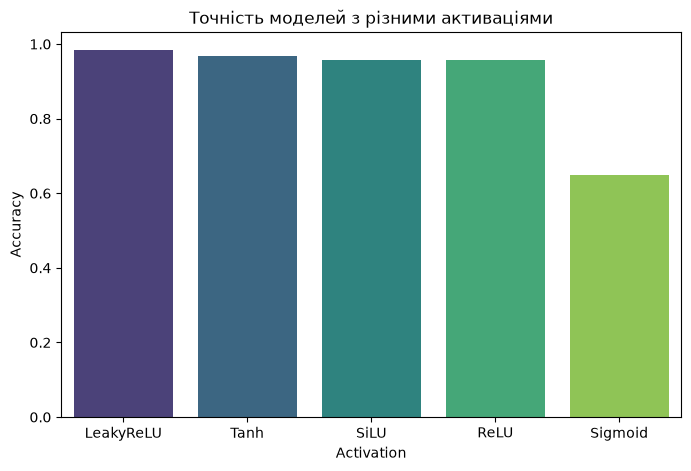

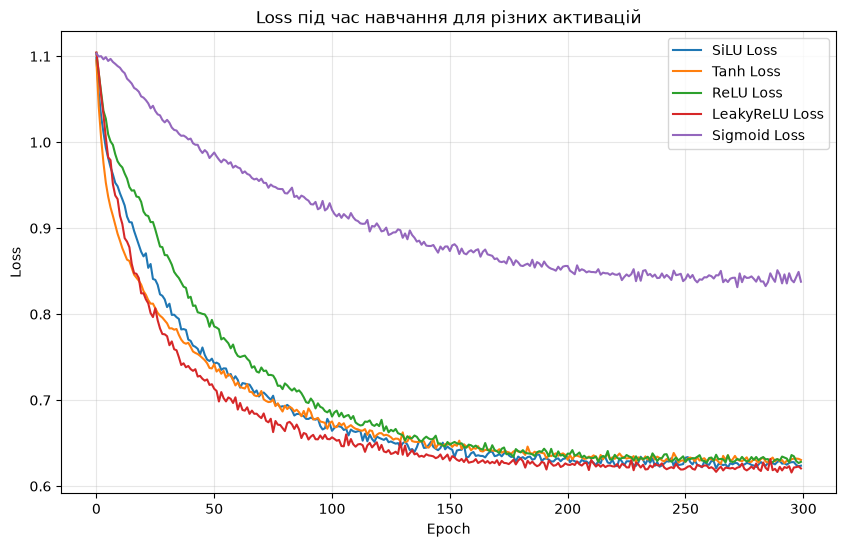

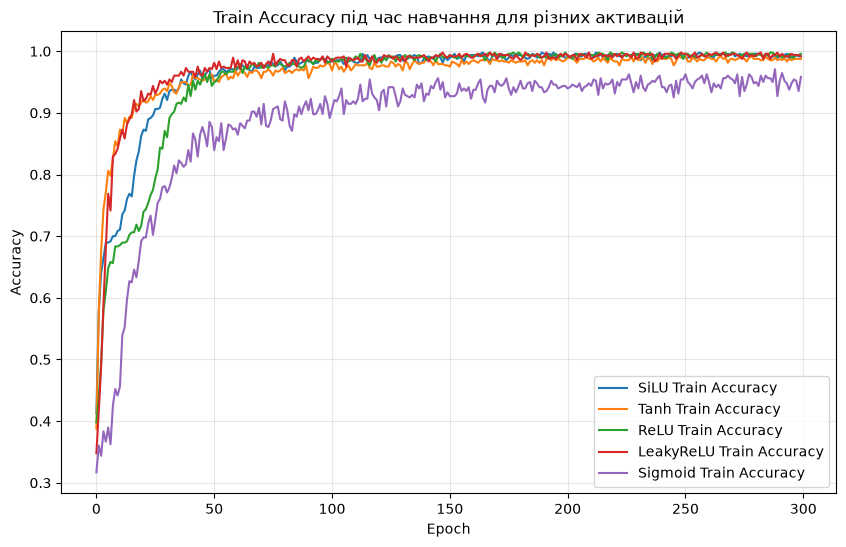

In [2]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
import torch
from torch import nn
import seaborn as sns
import matplotlib.pyplot as plt

# ---2--- Підготовка даних
df = pd.read_csv("anticheat_dataset.csv")

df["KD_ratio"] = df["Kills"] / (df["Deaths"] + 1)               
df["HitRate"] = df["ShotsHit"] / (df["ShotsFired"] + 1)         
df["DamagePerKill"] = df["DamagePerMatch"] / (df["Kills"] + 1)  
df["HS_KD_Anomaly"] = df["HeadshotPercent"] / (df["KD_ratio"] + 1e-5) 
df["Survival_KD_Ratio"] = df["SurvivalRate"] / (df["KD_ratio"] + 1e-5) 
df["Reaction_KD_Ratio"] = df["ReactionTime"] / (df["KD_ratio"] + 1e-5) 
df["Efficiency_Index"] = (df["Kills"] + df["DamagePerMatch"]) / (df["ShotsFired"] + df["Deaths"] + 1)
df["Accuracy_Kills_Ratio"] = df["Accuracy"] / (df["Kills"] + 1)
df["Reaction_Accuracy_Ratio"] = df["ReactionTime"] / (df["Accuracy"] + 1e-5)
df["SurvivalRate_feat"] = df["SurvivalRate"]
df["DamagePerMatch_feat"] = df["DamagePerMatch"]
df["SurvivalRate_feat"] = df["SurvivalRate"]
df["DamagePerMatch_feat"] = df["DamagePerMatch"]
df["Survival_Kills_Ratio"] =df["SurvivalRate"] / (df["Kills"] + 1)
# формуємо X і y
X = df.drop("Class", axis=1)
y = LabelEncoder().fit_transform(df["Class"])

# нормалізація
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# розділення на train/test
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

# перетворення у тензори
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

# ---3--- Модель
class AntiCheatNet(nn.Module):
    def __init__(self, input_size, activation=nn.ReLU):
        super().__init__()
        
        self.hidden = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.LayerNorm(128),
            activation(),
            nn.Dropout(0.25),
            
            nn.Linear(128, 64),
            nn.LayerNorm(64),
            activation(),
            nn.Dropout(0.2),
            
            nn.Linear(64, 32),
            nn.LayerNorm(32),
            activation(),
            nn.Dropout(0.15),
            
            nn.Linear(32, 16),
            nn.LayerNorm(16),
            activation(),
            nn.Dropout(0.1)
        )
        
        self.output = nn.Linear(16, 3) 
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        x = self.hidden(x)
        logits = self.output(x)
        probs = self.softmax(logits)
        return probs


def train_model(activation, epochs=300):
    model = AntiCheatNet(X_train_tensor.shape[1], activation)
    
    class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
    )
    weights = torch.tensor(class_weights, dtype=torch.float32)
    criterion = nn.CrossEntropyLoss(weight=weights, label_smoothing=0.05)

    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    
    history_loss = []
    history_acc = []

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        
        logits = model(X_train_tensor)
        
        loss = criterion(logits, y_train_tensor)
        loss.backward()
        optimizer.step()
        scheduler.step()


        # точність на train
        preds = logits.argmax(dim=1)
        acc = (preds == y_train_tensor).float().mean().item()
        
        history_loss.append(loss.item())
        history_acc.append(acc)
    
    return model, history_loss, history_acc


# ---4--- Експеримент з активаціями
activations = {
    "SiLU": nn.SiLU,
    "Tanh": nn.Tanh,
    "ReLU": nn.ReLU,
    "LeakyReLU": nn.LeakyReLU,
    "Sigmoid": nn.Sigmoid
}

results = {}
histories = {}

def threshold_predict(probs, thr_susp=0.40, thr_strong=0.55):
    preds = []
    for p in probs:
        if p[2] > thr_susp:   # Suspicious
            preds.append(2)
        elif p[1] > thr_strong: # Strong
            preds.append(1)
        else:
            preds.append(0) # Normal
    return torch.tensor(preds)
    
for name, act in activations.items():
    model, history_loss, history_acc = train_model(act, epochs=300)
    model.eval()
    with torch.no_grad():
        logits = model(X_test_tensor)
        probs = torch.softmax(logits, dim=1).cpu().numpy()
        preds_tensor = threshold_predict(probs, thr_susp=0.40, thr_strong=0.45)

        acc = (preds_tensor == y_test_tensor).float().mean().item()
    results[name] = round(acc, 3)
    histories[name] = {"loss": history_loss, "acc": history_acc}

print("Результати:", results)

best_act_name = max(results, key=results.get)
best_model, best_loss, best_acc = train_model(activations[best_act_name], epochs=150)
best_model.eval()
print(f"Найкраща активація: {best_act_name} → точність {results[best_act_name]:.3f}\n")

# Visualization

results_df = pd.DataFrame({
    "Activation": list(results.keys()),
    "Test Accuracy": list(results.values())
}).sort_values("Test Accuracy", ascending=False)

print("Порівняння точності моделей:")
display(results_df)

plt.figure(figsize=(8,5))
sns.barplot(
    x="Activation", 
    y="Test Accuracy", 
    data=results_df, 
    hue="Activation",   
    palette="viridis", 
    legend=False           
)

plt.title("Точність моделей з різними активаціями")
plt.ylabel("Accuracy")
plt.show()


plt.figure(figsize=(10,6))
for name, hist in histories.items():
    plt.plot(hist["loss"], label=f"{name} Loss")
plt.title("Loss під час навчання для різних активацій")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,6))
for name, hist in histories.items():
    plt.plot(hist["acc"], label=f"{name} Train Accuracy")
plt.title("Train Accuracy під час навчання для різних активацій")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



In [5]:
def predict_player(stats_list, model=best_model, scaler=scaler):
    kills, deaths, accuracy, headshot, dmg, surv, dist, shots_fired, shots_hit, react = stats_list
    
    player_dict = {
        "Kills": kills,
        "Deaths": deaths,
        "Accuracy": accuracy / 100.0, 
        "HeadshotPercent": headshot / 100.0,
        "DamagePerMatch": dmg,
        "SurvivalRate": surv / 100.0,
        "AverageKillDistance": dist,
        "ShotsFired": shots_fired,
        "ShotsHit": shots_hit,
        "ReactionTime": react
    }
    
    player_dict["KD_ratio"] = player_dict["Kills"] / (player_dict["Deaths"] + 1)
    player_dict["HitRate"] = player_dict["ShotsHit"] / (player_dict["ShotsFired"] + 1)
    player_dict["DamagePerKill"] = player_dict["DamagePerMatch"] / (player_dict["Kills"] + 1)
    player_dict["HS_KD_Anomaly"] = player_dict["HeadshotPercent"] / (player_dict["KD_ratio"] + 1e-5)
    player_dict["Survival_KD_Ratio"] = player_dict["SurvivalRate"] / (player_dict["KD_ratio"] + 1e-5)
    player_dict["Reaction_KD_Ratio"] = player_dict["ReactionTime"] / (player_dict["KD_ratio"] + 1e-5)
    player_dict["Efficiency_Index"] = (player_dict["Kills"] + player_dict["DamagePerMatch"]) / (
        player_dict["ShotsFired"] + player_dict["Deaths"] + 1
    )
    player_dict["Accuracy_Kills_Ratio"] = player_dict["Accuracy"] / (player_dict["Kills"] + 1)
    player_dict["Reaction_Accuracy_Ratio"] = player_dict["ReactionTime"] / (player_dict["Accuracy"] + 1e-5)
    player_dict["SurvivalRate_feat"] = player_dict["SurvivalRate"]
    player_dict["DamagePerMatch_feat"] = player_dict["DamagePerMatch"]
    player_dict["SurvivalRate_feat"] = player_dict["SurvivalRate"]
    player_dict["DamagePerMatch_feat"] = player_dict["DamagePerMatch"]
    player_dict["Survival_Kills_Ratio"] = player_dict["SurvivalRate"] / (player_dict["Kills"] + 1)


    x = pd.DataFrame([player_dict])
    x_scaled = scaler.transform(x)
    x_tensor = torch.tensor(x_scaled, dtype=torch.float32)
    
    with torch.no_grad():
        logits = model(x_tensor)
        probs = torch.softmax(logits, dim=1).numpy()[0]
    
    classes = ["Normal", "Strong", "Suspicious"]
    result = {classes[i]: round(float(probs[i]*100), 1) for i in range(3)}
    
    verdict = max(result, key=result.get)
    print(" | ".join([f"{k} — {v}%" for k,v in result.items()]),
          f"→ Вердикт: {verdict.upper()}")
    return result


# --- приклад ---
test_player = [25, 5, 65.0, 55.0, 1800, 80.0, 1500, 1200, 780, 200]
predict_player(test_player, model=best_model, scaler=scaler)

hard_examples = {
    # --- підозрілі приклади ---
    "HighHeadshotLowKD": [8, 12, 45.0, 80.0, 700, 40.0, 1200, 900, 400, 220],  
    # Очікувано: Suspicious → дуже високий % хедшотів при низькому KD, виглядає неприродно.

    "FastReactionLowAccuracy": [15, 10, 25.0, 15.0, 900, 60.0, 800, 2000, 500, 120],  
    # Очікувано: Suspicious → реакція 120 мс надто швидка, але точність низька, схоже на чіт.

    "HighDamageLowSurvival": [28, 20, 55.0, 35.0, 2500, 20.0, 2000, 3000, 1600, 210],  
    # Очікувано: Suspicious → дуже великий урон при низькому виживанні, статистика нелогічна.

    "PerfectAccuracyFewKills": [5, 3, 95.0, 60.0, 400, 70.0, 1500, 200, 190, 250],  
    # Очікувано: Suspicious → майже ідеальна точність при малих кіллах, виглядає нереально.

    "BadStatsFastReaction": [2, 15, 10.0, 5.0, 150, 10.0, 500, 3000, 300, 90],  
    # Очікувано: Suspicious → дуже погана статистика, але реакція 90 мс, що підозріло.

    "HighAccuracyLowDamage": [12, 8, 92.0, 40.0, 500, 70.0, 1000, 300, 276, 240],  
    # Очікувано: Suspicious → майже ідеальна точність, але низький урон, нелогічно.

    "AggressiveButLowSurvival": [30, 25, 55.0, 25.0, 2200, 15.0, 1800, 2500, 1375, 210],  
    # Очікувано: Suspicious → багато кіллів і урону, але виживання лише 15%, дивна поведінка.

    "PerfectHeadshotButFewKills": [4, 6, 50.0, 100.0, 300, 40.0, 900, 600, 300, 200],  
    # Очікувано: Suspicious → 100% хедшоти при малих кіллах, виглядає як чіт.

    "BalancedButExtremeDistance": [18, 10, 55.0, 30.0, 1200, 60.0, 4800, 1500, 825, 220],  
    # Очікувано: Suspicious → нормальні показники, але середня дистанція 4800, що нереально.

    # --- нормальні приклади ---
    "BalancedStats": [10, 12, 42.0, 20.0, 700, 55.0, 1000, 1200, 500, 300],  
    # Очікувано: Normal → середні показники, нічого підозрілого.

    "SlowReactionButGoodKD": [12, 8, 50.0, 25.0, 900, 60.0, 1200, 1000, 500, 420],  
    # Очікувано: Normal → повільна реакція, але статистика збалансована.

    # --- сильні приклади ---
    "HighKDButAverageAccuracy": [22, 6, 55.0, 35.0, 1600, 75.0, 1400, 2000, 1100, 230],  
    # Очікувано: Strong → високий KD, хороший урон, точність середня, виглядає як сильний гравець.

    "HighAccuracyButReasonableKD": [20, 5, 60.0, 35.0, 1500, 85.0, 1300, 1800, 1080, 480],  
    # Очікувано: Strong → висока точність, але KD адекватний, виглядає як сильний гравець.

    "AggressiveStrongPlayer": [28, 9, 60.0, 45.0, 2000, 80.0, 1700, 2500, 1500, 190],
    # Очікувано: Strong → багато кіллів, високий урон, хороше виживання, типовий сильний гравець.
    "LowKillsHighSurvival": [5, 2, 40.0, 20.0, 600, 90.0, 1000, 800, 320, 350],
    # Очікувано: Normal → мало кіллів, але дуже високе виживання, типовий обережний гравець.

    "ExtremeHeadshotAccuracy": [18, 12, 70.0, 95.0, 1800, 55.0, 1400, 2000, 1400, 250],
    # Очікувано: Suspicious → надто високий % хедшотів при середньому KD, виглядає неприродно.

    "TankyPlayer": [25, 15, 50.0, 30.0, 2200, 85.0, 1200, 2500, 1250, 400],
    # Очікувано: Strong → багато кіллів, високий урон і виживання, типовий сильний «танковий» гравець.

    "LowAccuracyButHighKD": [22, 7, 25.0, 20.0, 1500, 70.0, 1300, 3000, 750, 280],
    # Очікувано: Suspicious → KD високий, але точність дуже низька, виглядає нелогічно.

    "AverageAllAround": [12, 10, 50.0, 30.0, 1100, 60.0, 1200, 1500, 750, 300],
    # Очікувано: Normal → усі показники середні, без екстремальних значень.
}

hardest_examples = {
    "FastReactionLowAccuracy": [15, 10, 25.0, 15.0, 900, 60.0, 800, 2000, 500, 120],  
    # Очікувано: Suspicious → надто швидка реакція при низькій точності

    "HighDamageLowSurvival": [28, 20, 55.0, 35.0, 2500, 20.0, 2000, 3000, 1600, 210],  
    # Очікувано: Suspicious → дуже великий урон при низькому виживанні

    "BadStatsFastReaction": [2, 15, 10.0, 5.0, 150, 10.0, 500, 3000, 300, 90],  
    # Очікувано: Suspicious → дуже погана статистика, але реакція 90 мс

    "TankyPlayer": [25, 15, 50.0, 30.0, 2200, 85.0, 1200, 2500, 1250, 400],  
    # Очікувано: Strong → багато кіллів, високий урон і виживання

    "LowAccuracyButHighKD": [22, 7, 25.0, 20.0, 1500, 70.0, 1300, 3000, 750, 280]  
    # Очікувано: Suspicious → KD високий, але точність дуже низька
}

hard_examples_new = {
    # --- екстремальні/чітерські приклади ---
    "Test1": [30, 5, 20, 25, 3500, 70, 55, 1000, 999999, 230],
    # Очікувано: Suspicious → 999999 влучань при 1000 пострілах, неможливо.

    "NegativeValuesTest": [-50, -10, -100.0, -100.0, -5000, -100.0, -50.0, -1000, -500, -200],
    # Очікувано: Suspicious → від’ємні значення, некоректна статистика.

    "AFKAfterKills": [25, 10, 40, 45, 3000, 55, 35, 550, 220, 190],
    # Очікувано: Suspicious → багато кіллів, але потім різке падіння активності (AFK/смерті).
}

print("Hard lenth: ",len(hard_examples))

print()
for name, player in hard_examples.items():
    print(f"\n{name}:")
    predict_player(player)

print("\n__=HARD==MODE=__\n")
for name, player in hardest_examples.items():
    print(f"\n{name}:")
    predict_player(player)



print("\n__=NEW==MODE=__\n")
for name, player in hard_examples_new.items():
    print(f"\n{name}:")
    predict_player(player)



print("\n__=NEW==MODE=__\n")
for name, player in hard_examples_new.items():
    print(f"\n{name}:")
    predict_player(player)


Normal — 22.7% | Strong — 54.7% | Suspicious — 22.6% → Вердикт: STRONG
Hard lenth:  19


HighHeadshotLowKD:
Normal — 50.7% | Strong — 24.9% | Suspicious — 24.4% → Вердикт: NORMAL

FastReactionLowAccuracy:
Normal — 47.8% | Strong — 27.0% | Suspicious — 25.2% → Вердикт: NORMAL

HighDamageLowSurvival:
Normal — 23.7% | Strong — 22.8% | Suspicious — 53.5% → Вердикт: SUSPICIOUS

PerfectAccuracyFewKills:
Normal — 23.7% | Strong — 22.9% | Suspicious — 53.4% → Вердикт: SUSPICIOUS

BadStatsFastReaction:
Normal — 43.1% | Strong — 25.8% | Suspicious — 31.1% → Вердикт: NORMAL

HighAccuracyLowDamage:
Normal — 24.5% | Strong — 24.2% | Suspicious — 51.3% → Вердикт: SUSPICIOUS

AggressiveButLowSurvival:
Normal — 23.7% | Strong — 22.8% | Suspicious — 53.5% → Вердикт: SUSPICIOUS

PerfectHeadshotButFewKills:
Normal — 50.7% | Strong — 24.9% | Suspicious — 24.5% → Вердикт: NORMAL

BalancedButExtremeDistance:
Normal — 23.7% | Strong — 22.8% | Suspicious — 53.5% → Вердикт: SUSPICIOUS

BalancedStats:
Normal — 